# Circular Text Unwrap — herramienta interactiva

Herramienta independiente para "desenrollar" anillos de texto circular concéntricos
en tiras horizontales rectas. Útil para examinar manuscritos circulares (Voynich,
diagramas astrológicos, calendarios circulares, etc.) donde el texto está dispuesto
en arcos que dificultan la lectura directa.

**Esto NO es parte de la serie de notebooks de investigación del proyecto.** Es una
utilidad de exploración. Cambia los parámetros del bloque de configuración a mano y
re-ejecuta las celdas siguientes para probar distintos centros, radios y resoluciones.

**Cómo usarlo**:
1. Ejecuta la celda de imports
2. Edita el bloque de **PARÁMETROS** con la imagen y los valores que quieras probar
3. Ejecuta la celda de **previsualización** — verás la imagen original con un
   marcador del centro y dos círculos delimitando la banda que vas a desenrollar.
   Si los círculos no encajan con el anillo de texto que quieres extraer, ajusta
   `cx`, `cy`, `r_min`, `r_max` y vuelve a ejecutar
4. Cuando los círculos encajen, ejecuta la celda **unwrap** que produce la tira
   desenrollada. La interpolación es bilineal (calidad mejor que vecino más cercano)
5. La celda de **guardado** escribe el resultado a disco con un nombre descriptivo

**Tips**:
- Si el centro no está bien centrado, los anillos saldrán como ondas en lugar de
  como líneas rectas. Ajusta `cx` y `cy` y prueba de nuevo.
- Empieza con `n_angles_per_pixel = 1` para algo rápido. Sube a 2 o 4 si quieres
  más detalle horizontal.
- Para anillos finos (un solo anillo de texto), usa `r_min` y `r_max` muy próximos.
  Para varios anillos a la vez, abre el rango.
- El parámetro `start_angle_deg` define qué punto del círculo aparece en la
  izquierda de la tira. 0 = arriba (12 en punto), 90 = derecha (3 en punto), etc.

## Imports

In [99]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import os

# Configure matplotlib for inline display in the notebook
%matplotlib inline
plt.rcParams['figure.dpi'] = 100

## PARÁMETROS — edita estos valores a mano

Todos los parámetros que controlan el unwrap están aquí. Cambia los valores y
re-ejecuta las celdas siguientes.

In [100]:
# === IMAGEN DE ENTRADA ===
input_image = '../historic/f57v.jpg'  # ruta a la imagen (relativa al notebook)

# === CENTRO DEL DIAGRAMA ===
# Coordenadas (en píxeles) del centro del diagrama circular en la imagen
# Para f57v.jpg el centro está aproximadamente en (1514, 1696)
cx = 1740
cy = 1450

# === RADIOS ===
# Banda anular a desenrollar: r_min = radio interior, r_max = radio exterior
# El unwrap captura todos los píxeles entre estos dos radios
# Para todo el diagrama de f57v: r_min=200, r_max=1450
# Para sólo el segundo anillo (alfabeto): r_min=1080, r_max=1180 (aproximadamente)
# r_min = 200 # para todo el circulo
r_min = 830 # para segundo anillo
# r_max = 1200 # para todo el circulo
r_max = 1000 # para segundo anillo

# === RESOLUCIÓN ANGULAR ===
# Cuántos píxeles de ancho tendrá la tira desenrollada por cada grado del círculo
# Valores típicos:
#   1 = rápido, baja resolución horizontal (360 píxeles totales)
#   5 = balanceado (1800 píxeles)
#   10 = alta resolución horizontal (3600 píxeles)
samples_per_degree = 10

# === ÁNGULO INICIAL ===
# Qué punto del círculo aparece en el extremo IZQUIERDO de la tira desenrollada
# 0 grados = arriba (12 en punto)
# 90 grados = derecha (3 en punto)
# 180 grados = abajo (6 en punto)
# 270 grados = izquierda (9 en punto)
start_angle_deg = 302

# === DIRECCIÓN ===
# 'cw' = sentido horario (típico para texto circular)
# 'ccw' = sentido antihorario
direction = 'cw'

# === ORIENTACIÓN VERTICAL ===
# 'outside_top' = el radio exterior va arriba en la tira (anillo más exterior arriba)
# 'inside_top'  = el radio interior va arriba (centro arriba)
vertical = 'outside_top'

# === RUTA DE SALIDA ===
output_image = '../historic/unwrap_test.jpg'  # se sobrescribirá cada vez

## Previsualización — verifica que el centro y los radios encajan

Esta celda dibuja la imagen original con:
- Una **cruz roja** marcando el centro `(cx, cy)`
- Un **círculo verde** del radio `r_min`
- Un **círculo amarillo** del radio `r_max`

Si los dos círculos delimitan correctamente el anillo de texto que quieres extraer,
sigue adelante. Si no, ajusta los parámetros del bloque anterior y vuelve a ejecutar
esta celda.

Loaded ../historic/f57v.jpg: 3028 x 3769 pixels


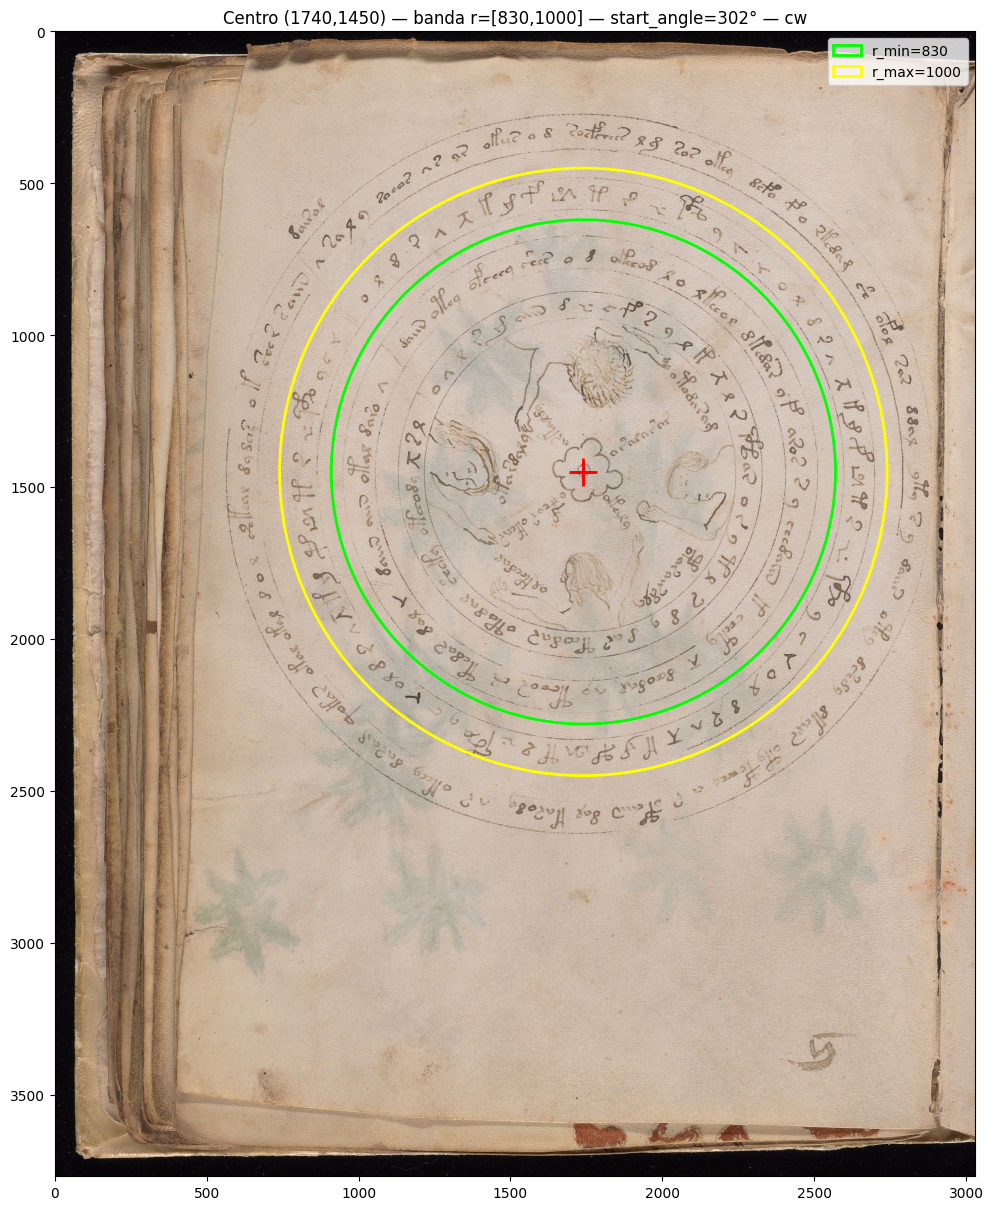

In [101]:
# Load the source image
img = Image.open(input_image)
arr = np.array(img)
H, W = arr.shape[:2]
print(f'Loaded {input_image}: {W} x {H} pixels')

# Display with center marker and ring boundaries
fig, ax = plt.subplots(1, 1, figsize=(10, 10 * H / W))
ax.imshow(arr)

# Center cross
ax.plot([cx-30, cx+30], [cy, cy], 'r-', linewidth=2)
ax.plot([cx, cx], [cy-30, cy+30], 'r-', linewidth=2)
ax.plot(cx, cy, 'r+', markersize=20, markeredgewidth=2)

# Inner radius circle (green)
inner_circle = Circle((cx, cy), r_min, fill=False, color='lime', linewidth=2, label=f'r_min={r_min}')
ax.add_patch(inner_circle)

# Outer radius circle (yellow)
outer_circle = Circle((cx, cy), r_max, fill=False, color='yellow', linewidth=2, label=f'r_max={r_max}')
ax.add_patch(outer_circle)

ax.set_title(f'Centro ({cx},{cy}) — banda r=[{r_min},{r_max}] — start_angle={start_angle_deg}° — {direction}')
ax.legend(loc='upper right')
ax.set_xlim(0, W)
ax.set_ylim(H, 0)
plt.tight_layout()
plt.show()

## Unwrap polar (interpolación bilineal)

Esta celda hace el desenrollado polar de la banda anular definida por los parámetros.
Usa interpolación bilineal para mejor calidad que el vecino más cercano.

El resultado es una imagen rectangular donde:
- El **eje horizontal** representa el ángulo (longitud del arco desenrollado)
- El **eje vertical** representa el radio (la "altura" de la banda anular)
- Cada anillo de texto del original aparece como una **franja horizontal** en el resultado

Si el centro está mal estimado, los anillos saldrán como **ondas** (sinusoides) en
vez de líneas rectas — ése es el indicador para corregir `cx`, `cy`.

In [102]:
from scipy.ndimage import map_coordinates


def polar_unwrap(arr, cx, cy, r_min, r_max,
                 samples_per_degree=5,
                 start_angle_deg=0,
                 direction='cw',
                 vertical='outside_top'):
    """Unwrap an annular band of an image into a horizontal strip.

    Vectorized using scipy.ndimage.map_coordinates with bilinear interpolation
    (order=1). MUCH faster than nested Python loops.

    Parameters
    ----------
    arr : numpy array (H, W, C) or (H, W)
        Source image as numpy array
    cx, cy : int
        Center of the circular diagram, in pixels
    r_min, r_max : int
        Inner and outer radius of the band to unwrap, in pixels
    samples_per_degree : int
        Horizontal resolution: pixels per degree of arc
    start_angle_deg : float
        Where the strip starts (left edge). 0 = top of circle, 90 = right.
    direction : 'cw' or 'ccw'
        Reading direction (clockwise or counter-clockwise)
    vertical : 'outside_top' or 'inside_top'
        Which radius appears at the top of the unwrapped strip

    Returns
    -------
    unwrapped : numpy array (n_radii, n_angles, C) — same dtype as arr
    """
    n_angles = int(360 * samples_per_degree)
    n_radii = r_max - r_min + 1

    sign = -1.0 if direction == 'ccw' else 1.0
    start_rad = np.deg2rad(start_angle_deg - 90)  # offset so 0 deg = top

    # Build the angle and radius grids
    thetas = start_rad + sign * np.linspace(0, 2 * np.pi, n_angles, endpoint=False)
    if vertical == 'outside_top':
        radii = np.arange(r_max, r_min - 1, -1, dtype=np.float32)
    else:
        radii = np.arange(r_min, r_max + 1, dtype=np.float32)

    # 2D meshgrid: (n_radii, n_angles)
    R, T = np.meshgrid(radii, thetas, indexing='ij')

    # Cartesian coordinates of each sample
    xs = cx + R * np.cos(T)
    ys = cy + R * np.sin(T)

    # Sample using bilinear interpolation (order=1)
    if arr.ndim == 3:
        channels = []
        for c in range(arr.shape[2]):
            sampled = map_coordinates(arr[:, :, c], [ys, xs],
                                       order=1, mode='constant', cval=0)
            channels.append(sampled)
        unwrapped = np.stack(channels, axis=-1).astype(arr.dtype)
    else:
        unwrapped = map_coordinates(arr, [ys, xs],
                                     order=1, mode='constant', cval=0).astype(arr.dtype)

    return unwrapped


# Run the unwrap with the current parameters
print(f'Running unwrap on {input_image}...')
print(f'  Center: ({cx}, {cy})')
print(f'  Radii: {r_min} to {r_max} ({r_max - r_min + 1} px height)')
print(f'  Samples/degree: {samples_per_degree} ({360 * samples_per_degree} angles)')
print(f'  Start angle: {start_angle_deg}°  Direction: {direction}  Vertical: {vertical}')

import time
t0 = time.time()
unwrapped = polar_unwrap(arr, cx, cy, r_min, r_max,
                          samples_per_degree=samples_per_degree,
                          start_angle_deg=start_angle_deg,
                          direction=direction,
                          vertical=vertical)
print(f'Unwrapped shape: {unwrapped.shape}  ({time.time()-t0:.2f}s)')

Running unwrap on ../historic/f57v.jpg...
  Center: (1740, 1450)
  Radii: 830 to 1000 (171 px height)
  Samples/degree: 10 (3600 angles)
  Start angle: 302°  Direction: cw  Vertical: outside_top
Unwrapped shape: (171, 3600, 3)  (0.05s)


## Mostrar el resultado

Si los anillos salen como **líneas horizontales rectas** = el centro está bien.
Si salen como **ondas / sinusoides** = el centro está mal, ajusta `cx`/`cy`.

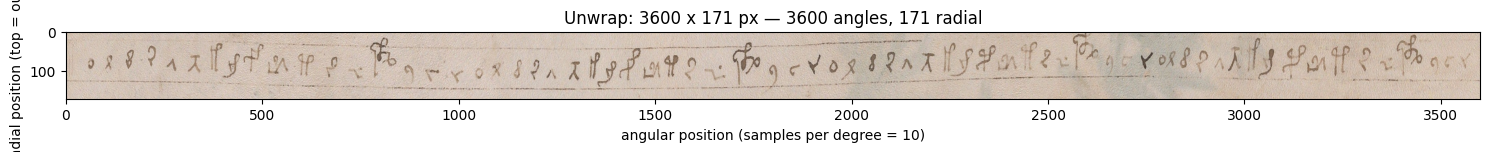

In [103]:
# Display the unwrapped strip
unwrap_img = Image.fromarray(unwrapped)
uw, uh = unwrap_img.size

fig, ax = plt.subplots(1, 1, figsize=(15, max(2, 15 * uh / uw)))
ax.imshow(unwrapped)
ax.set_title(f'Unwrap: {uw} x {uh} px — {360 * samples_per_degree} angles, {r_max - r_min + 1} radial')
ax.set_xlabel(f'angular position (samples per degree = {samples_per_degree})')
ax.set_ylabel('radial position (top = outer)')
plt.tight_layout()
plt.show()

## Guardar el resultado

Escribe la tira desenrollada al disco en `output_image`. Edita la ruta arriba si
quieres conservar varios resultados con nombres distintos.

In [104]:
# Save to disk
unwrap_img = Image.fromarray(unwrapped)
unwrap_img.save(output_image, quality=95)
size_kb = os.path.getsize(output_image) / 1024
print(f'Saved {output_image} ({unwrap_img.size}, {size_kb:.0f} KB)')

Saved ../historic/unwrap_test.jpg ((3600, 171), 294 KB)


## Auxiliar — buscar el centro automáticamente

Si no estás seguro del centro exacto, esta celda hace varios unwraps con centros
ligeramente desplazados y muestra cuál tiene los anillos más rectos. Útil para
afinar `cx`/`cy`.

El criterio para "anillos más rectos" es la **varianza horizontal de los píxeles
oscuros** dentro de un perfil de fila — si las filas son rectas, la varianza es
baja; si son ondas, es alta.

In [105]:
from scipy.ndimage import gaussian_filter1d


def score_unwrap_straightness(unwrap_arr, n_rows_to_check=10):
    """Score how 'straight' the rings in an unwrap are.
    Lower score = straighter rings = better center estimate.

    The idea: if the rings are perfectly horizontal in the unwrap, the column-wise
    variance of dark pixels (text) should be high (a sharp dark band). If the rings
    are wavy due to bad center, the variance per column drops because the dark
    pixels are spread across different rows. We compute the inverse signal: how
    much each row deviates from its smoothed mean (the "wavyness" of the ring).
    """
    gray = unwrap_arr.mean(axis=2) if unwrap_arr.ndim == 3 else unwrap_arr
    h = gray.shape[0]
    sample_rows = np.linspace(h // 4, 3 * h // 4, n_rows_to_check, dtype=int)
    total_variance = 0.0
    for r in sample_rows:
        row = gray[r, :].astype(np.float32)
        smoothed = gaussian_filter1d(row, sigma=20)
        residual = row - smoothed
        total_variance += residual.var()
    return total_variance / n_rows_to_check


# === SEARCH PARAMETERS — edit these for the auto-search ===
search_radius_px = 30   # how far from current (cx,cy) to search
search_step_px = 10     # grid step

# For speed during search, use a NARROW radial band (just enough rows
# to score straightness) and LOW angular resolution
search_r_min = max(0, (r_min + r_max)//2 - 50)
search_r_max = (r_min + r_max)//2 + 50
search_samples_per_deg = 2

print(f'Searching center near ({cx}, {cy}) ± {search_radius_px}px in steps of {search_step_px}px')
print(f'  Quick scoring band: r=[{search_r_min}, {search_r_max}], '
      f'{360*search_samples_per_deg} angles')
print()
print(f'{"cx":>6s} {"cy":>6s} {"score":>10s}')
print('-' * 26)

import time
t0 = time.time()
best_score = float('inf')
best_cx, best_cy = cx, cy

for dx in range(-search_radius_px, search_radius_px + 1, search_step_px):
    for dy in range(-search_radius_px, search_radius_px + 1, search_step_px):
        try_cx = cx + dx
        try_cy = cy + dy
        u = polar_unwrap(arr, try_cx, try_cy, search_r_min, search_r_max,
                         samples_per_degree=search_samples_per_deg,
                         start_angle_deg=start_angle_deg,
                         direction=direction,
                         vertical=vertical)
        score = score_unwrap_straightness(u)
        marker = ''
        if score < best_score:
            best_score = score
            best_cx, best_cy = try_cx, try_cy
            marker = '  <- best so far'
        print(f'{try_cx:>6d} {try_cy:>6d} {score:>10.2f}{marker}')

print()
print(f'BEST CENTER: ({best_cx}, {best_cy}) with score {best_score:.2f} '
      f'(searched in {time.time()-t0:.1f}s)')
print(f'Update cx, cy in the parameters cell to these values and re-run.')

Searching center near (1740, 1450) ± 30px in steps of 10px
  Quick scoring band: r=[865, 965], 720 angles

    cx     cy      score
--------------------------
  1710   1420     401.36  <- best so far
  1710   1430     437.18
  1710   1440     450.91
  1710   1450     484.16
  1710   1460     485.21
  1710   1470     486.22
  1710   1480     457.77
  1720   1420     440.66
  1720   1430     495.35
  1720   1440     505.14
  1720   1450     514.38
  1720   1460     522.68
  1720   1470     503.35
  1720   1480     477.07
  1730   1420     437.96
  1730   1430     484.17
  1730   1440     519.51
  1730   1450     548.40
  1730   1460     563.67
  1730   1470     544.58
  1730   1480     501.63
  1740   1420     451.10
  1740   1430     467.65
  1740   1440     501.16
  1740   1450     533.11
  1740   1460     530.67
  1740   1470     519.84
  1740   1480     497.42
  1750   1420     428.51
  1750   1430     475.35
  1750   1440     480.05
  1750   1450     509.91
  1750   1460     484.88


## Notas y referencias rápidas

**Imágenes interesantes en `historic/`** para probar:

| Imagen | Centro aproximado | Notas |
|---|---|---|
| `f57v.jpg` | (1514, 1696) | Diagrama de cuatro nymphas con cuatro anillos concéntricos. Anillo del alfabeto en r ≈ 1080-1180 |
| `67r.jpg` | depende del crop | Diagrama astronómico con fases lunares |
| `f70r.jpg` | depende del crop | Sol antropomorfo con 16 rayos y leyendas radiales |
| `picatrix_p-150.jpg` ... `picatrix_p-155.jpg` | depende | Diagramas circulares "Spera Civitatum" del Picatrix |

**Errores comunes**:
- Si la imagen está rotada (un facsímil escaneado torcido), el unwrap también estará rotado
- Los anillos de texto del Voynich están escritos siguiendo la curva, así que al desenrollar
  el texto aparece **invertido en la mitad inferior del círculo** (porque las letras de
  abajo del círculo están "boca abajo" cuando se "estiran" rectas). Si quieres leerlas,
  rota 180° esa parte de la tira o cambia `start_angle_deg` para empezar por la mitad
  inferior.
- Para anillos donde el texto va de derecha a izquierda (algunas tradiciones árabes),
  usa `direction='ccw'`.

**Cómo encontrar el centro a mano**:
1. Empieza con un centro estimado (p. ej. el centro geométrico de la página)
2. Ejecuta la previsualización y mira si los círculos verde/amarillo encajan con
   los anillos de texto
3. Si están descentrados, mueve `cx` y/o `cy` 20-50 píxeles en la dirección
   contraria al desplazamiento que ves
4. Si no estás seguro, ejecuta la celda auxiliar de búsqueda automática